计算相关系数矩阵...

高度相关的特征对:
特征 2 (5.4956) 和 特征 3 (1.5315): 0.8701
特征 5 (36) 和 特征 128 (544.6334587657093): 0.9646
特征 7 (5) 和 特征 19 (10.811): 0.9959
特征 8 (38) 和 特征 9 (33): 0.9867
特征 8 (38) 和 特征 20 (87.62): 0.9992
特征 8 (38) 和 特征 21 (76.809): 0.9916
特征 8 (38) 和 特征 37 (5.1): 0.9685
特征 8 (38) 和 特征 38 (3): 0.9516
特征 9 (33) 和 特征 20 (87.62): 0.9864
特征 9 (33) 和 特征 21 (76.809): 0.9983
特征 9 (33) 和 特征 37 (5.1): 0.9553
特征 9 (33) 和 特征 38 (3): 0.9559
特征 10 (16.333333333333332) 和 特征 11 (12.11111111111111): 0.8403
特征 10 (16.333333333333332) 和 特征 22 (36.110033333333334): 0.9966
特征 10 (16.333333333333332) 和 特征 23 (28.61664814814815): 0.8452
特征 10 (16.333333333333332) 和 特征 39 (2.888888888888889): 0.9560
特征 10 (16.333333333333332) 和 特征 40 (1.1851851851851851): 0.8292
特征 11 (12.11111111111111) 和 特征 22 (36.110033333333334): 0.8728
特征 11 (12.11111111111111) 和 特征 23 (28.61664814814815): 0.9980
特征 11 (12.11111111111111) 和 特征 40 (1.1851851851851851): 0.9418
特征 12 (8) 和 特征 24 (15.9994): 0.9987
特征 12 (8) 和 特征 25 (54.8):

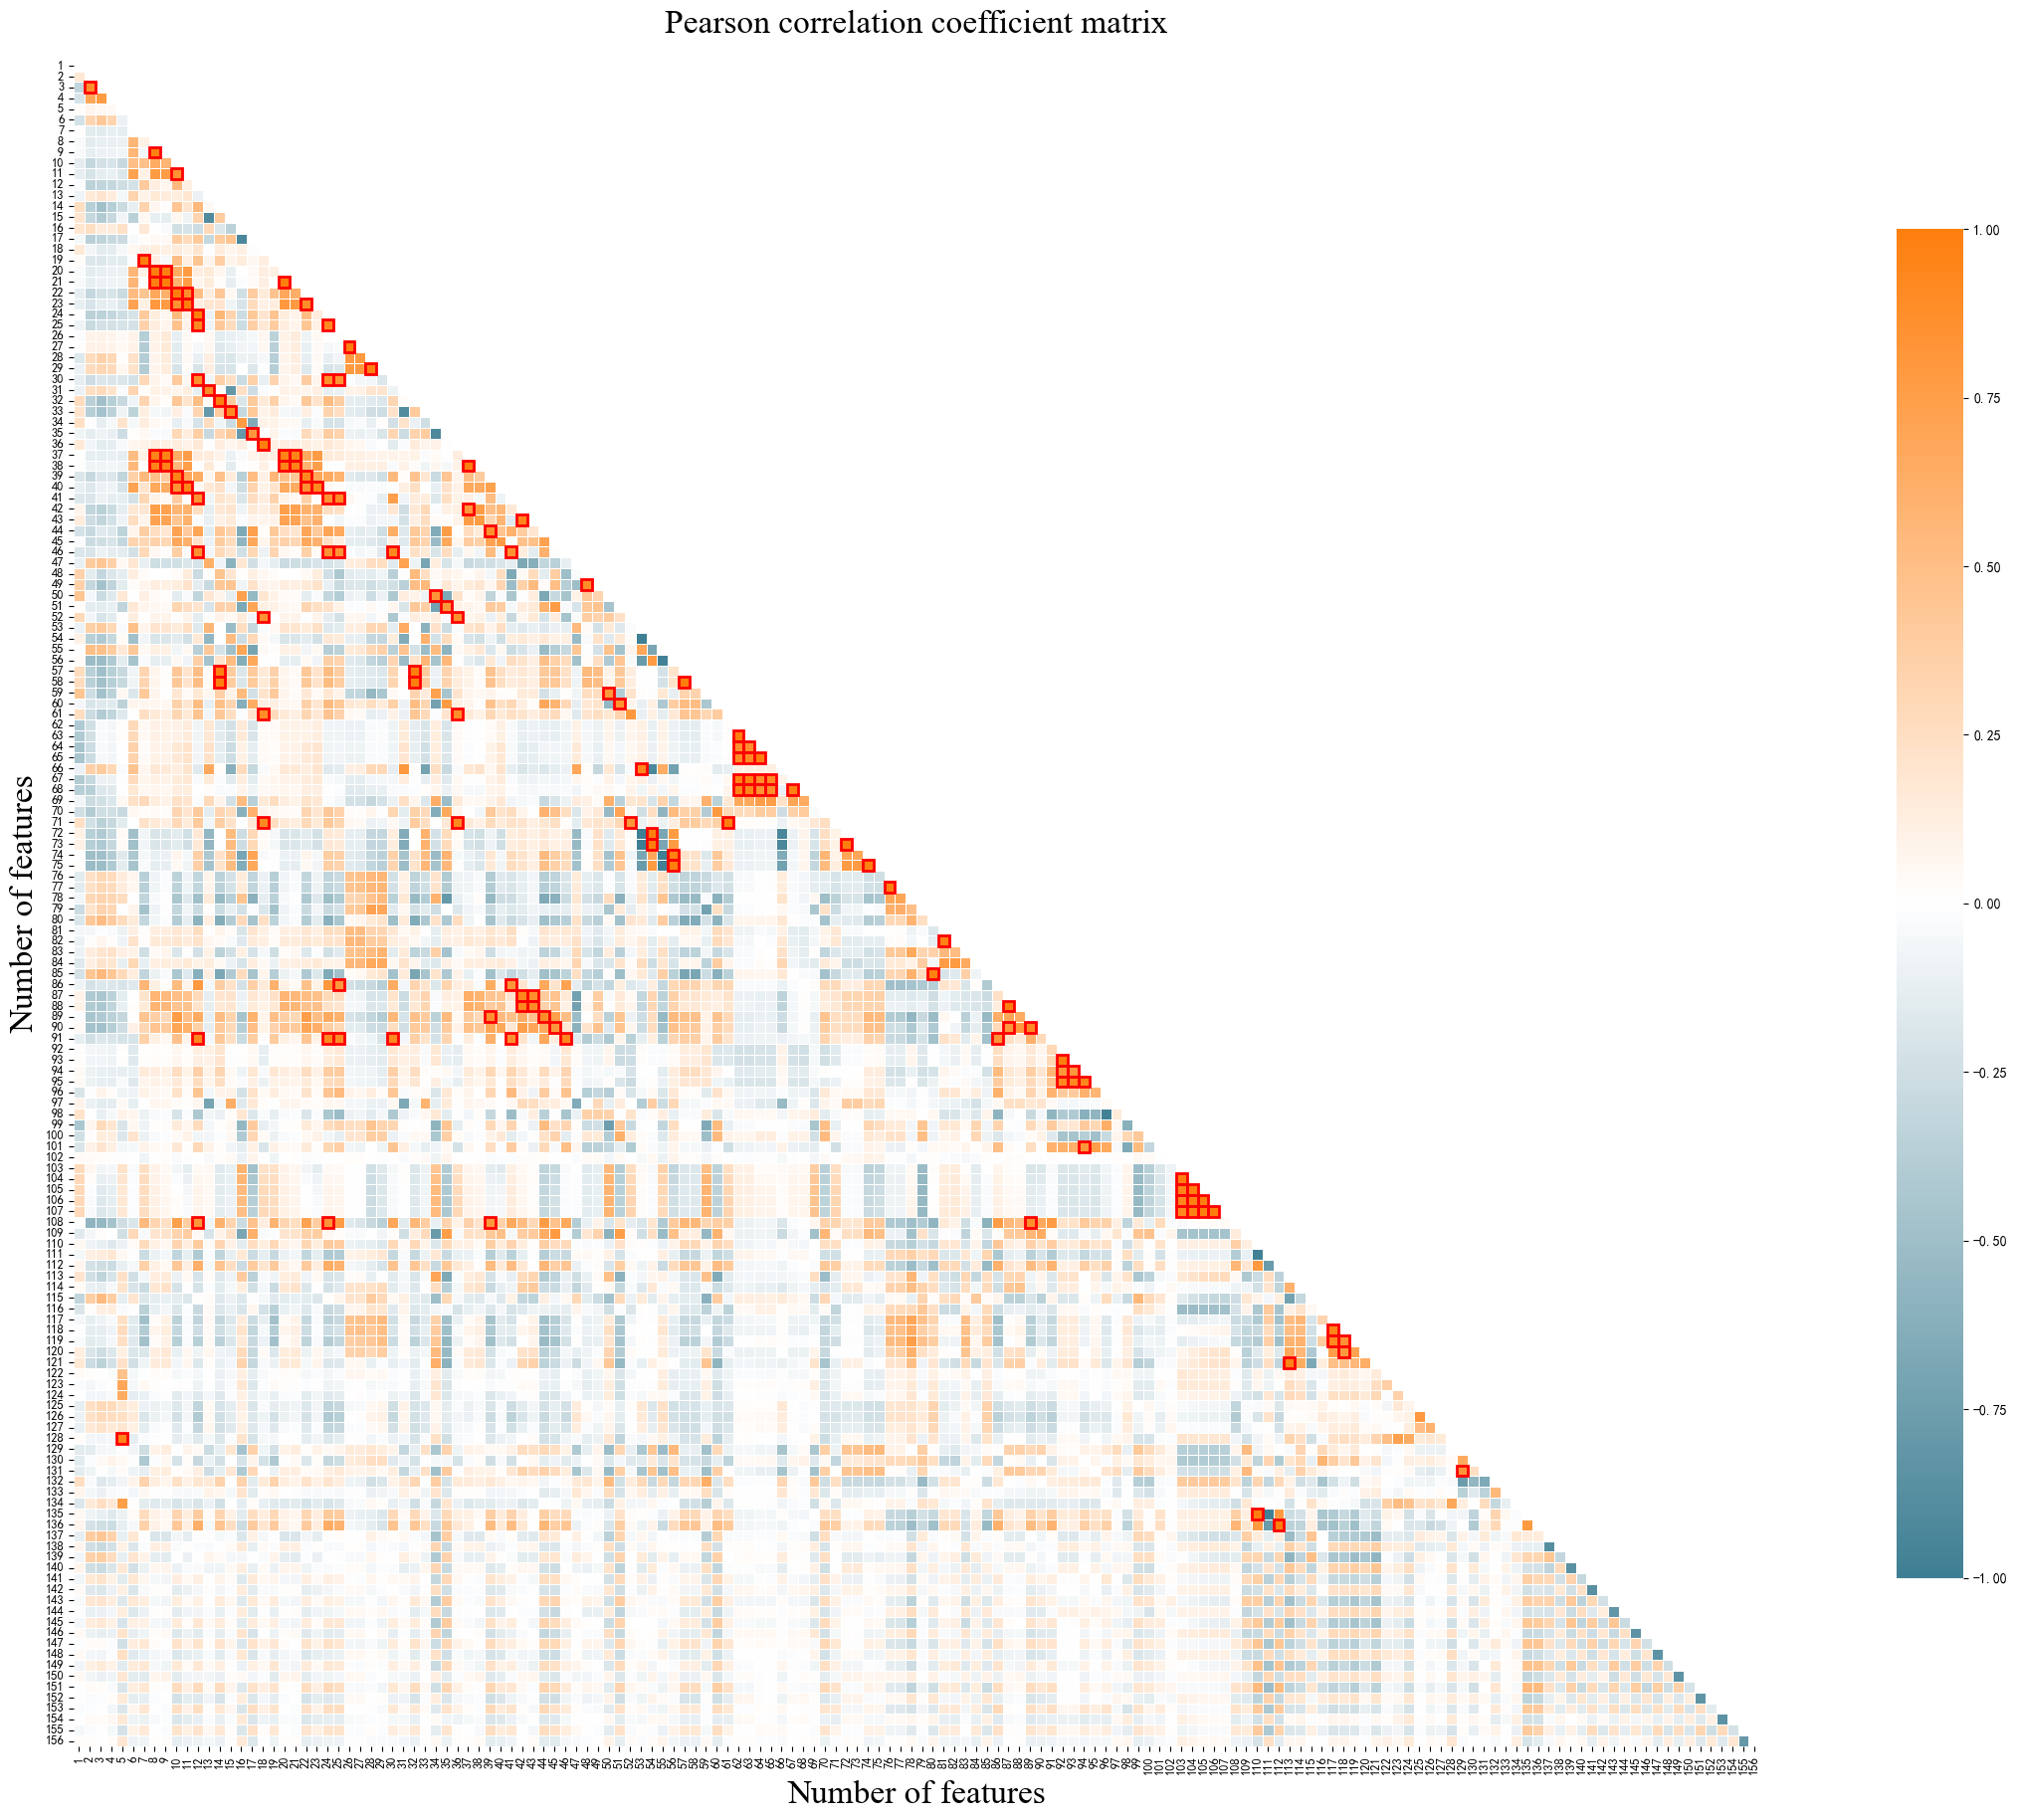


热力图已保存为 'correlation_heatmap.pdf'


In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap

# 设置中文字体支持（如果需要显示中文）
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False    # 用来正常显示负号

def analyze_correlations(file_path):
    """
    分析Excel文件中特征的皮尔逊相关系数
    
    参数:
    file_path (str): Excel文件路径
    """
    # 1. 读取Excel文件
    # 第一行为列名，从第二行开始读取数据
    df = pd.read_excel(file_path, header=0)
    
    # 2. 计算皮尔逊相关系数矩阵
    print("计算相关系数矩阵...")
    corr_matrix = df.corr(method='pearson')
    
    # 3. 准备绘图数据
    # 创建列索引映射（从1开始）
    col_index_map = {col: i+1 for i, col in enumerate(df.columns)}
    
    # 4. 找出相关系数>0.8的特征对 (注意您注释写的是>0.9，代码里是>0.8，这里保留您的原始逻辑)
    high_corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            corr_value = corr_matrix.iloc[i, j]
            if corr_value > 0.8:  # 考虑正相关>0.8的情况
                col1 = corr_matrix.columns[i]
                col2 = corr_matrix.columns[j]
                high_corr_pairs.append({
                    '特征1': col1,
                    '特征2': col2,
                    '相关系数': corr_value,
                    '索引1': col_index_map[col1],
                    '索引2': col_index_map[col2]
                })
    
    # 5. 打印高度相关的特征对
    print("\n高度相关的特征对:")
    for pair in high_corr_pairs:
        print(f"特征 {pair['索引1']} ({pair['特征1']}) 和 特征 {pair['索引2']} ({pair['特征2']}): {pair['相关系数']:.4f}")
    
    # 6. 绘制热力图
    print("\n绘制热力图...")
    plt.figure(figsize=(28, 22)) # PDF是矢量图，dpi参数在这里可以省略或保留，清晰度不受影响
    
    # 创建自定义颜色映射
    colors = ["#3f7f93", "#ffffff", "#ff7f0e"]
    cmap = LinearSegmentedColormap.from_list("custom_cmap", colors, N=256)
    
    # 创建掩码（隐藏上三角）
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    
    # 绘制基础热力图
    ax = sns.heatmap(
        corr_matrix, 
        mask=mask, 
        cmap=cmap, 
        center=0,
        vmin=-1, 
        vmax=1, 
        square=True, 
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
        annot=False  # 不显示数值，避免混淆
    )
    
    # 设置坐标轴标签为索引编号
    ax.set_xticks(np.arange(len(df.columns)) + 0.5) # 加上0.5让标签居中对齐格子
    ax.set_yticks(np.arange(len(df.columns)) + 0.5)
    ax.set_xticklabels([str(i+1) for i in range(len(df.columns))], fontsize=9, rotation=90)
    ax.set_yticklabels([str(i+1) for i in range(len(df.columns))], fontsize=9, rotation=0)
    
    # 添加特征编号对应关系
    plt.xlabel('Number of features', fontsize=24, fontname='Times New Roman')
    plt.ylabel('Number of features', fontsize=24, fontname='Times New Roman')
    
    # 添加标题
    plt.title('Pearson correlation coefficient matrix', fontsize=24, pad=20, fontname='Times New Roman')
    
    # 7. 标记相关系数高的格子（仅下三角）
    for pair in high_corr_pairs:
        # 获取特征索引
        i = list(df.columns).index(pair['特征1'])
        j = list(df.columns).index(pair['特征2'])
        
        # 确定哪个索引更大（下三角位置）
        row_idx = max(i, j)  # 行索引（较大的索引）
        col_idx = min(i, j)  # 列索引（较小的索引）
        
        # 仅在下三角区域添加红色边框标记
        rect = patches.Rectangle(
            (col_idx, row_idx),  # 左下角坐标 (x,y)
            1, 1, 
            linewidth=2, 
            edgecolor='red', 
            facecolor='none'
        )
        ax.add_patch(rect)

    # 8. 调整布局并保存为PDF
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.2)  # 为特征对应表留出空间
    
    # ================= 主要修改部分 =================
    # 保存为PDF格式，format='pdf' 可以确保生成矢量图
    save_path = 'correlation_heatmap.pdf'
    plt.savefig(save_path, format='pdf', bbox_inches='tight')
    # ================================================
    
    plt.show()
    
    print(f"\n热力图已保存为 '{save_path}'")

# 示例使用
if __name__ == "__main__":
    # 替换为您的Excel文件路径
    excel_file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\code\Pearson correlation\729×156.xlsx"
    
    # 执行分析
    analyze_correlations(excel_file_path)